Dataset loaded successfully!
Rows and columns: (956, 15)


,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


Column names:
['Unnamed: 0', 'Job Title', 'Salary Estimate', 'Job Description', 'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded', 'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         956 non-null    int64  
 1   Job Title          956 non-null    object 
 2   Salary Estimate    956 non-null    object 
 3   Job Description    956 non-null    object 
 4   Rating             956 non-null    float64
 5   Company Name       956 non-null    object 
 6   Location           956 non-null    object 
 7   Headquarters       956 non-null    object 
 8   Size               956 non-null    object 
 9   Founded            956 non-null    int64  
 10  Type of ownership  956 non-null    object 
 11  Industry           956

,job_count
role_group,
Data Scientist,357
Data Analyst,107


,job_title,role_group,Python,SQL,Excel
0,Data Scientist,Data Scientist,True,False,True
1,Healthcare Data Scientist,Data Scientist,True,False,False
2,Data Scientist,Data Scientist,True,True,True
3,Data Scientist,Data Scientist,True,False,False
4,Data Scientist,Data Scientist,True,True,False


,job_postings_mentioning_skill,percentage_of_postings
Statistics,344,74.1
Python,304,65.5
Machine Learning,279,60.1
SQL,267,57.5
Tableau,133,28.7
Excel,104,22.4
AWS,71,15.3
TensorFlow,64,13.8
Deep Learning,57,12.3
Power BI,49,10.6


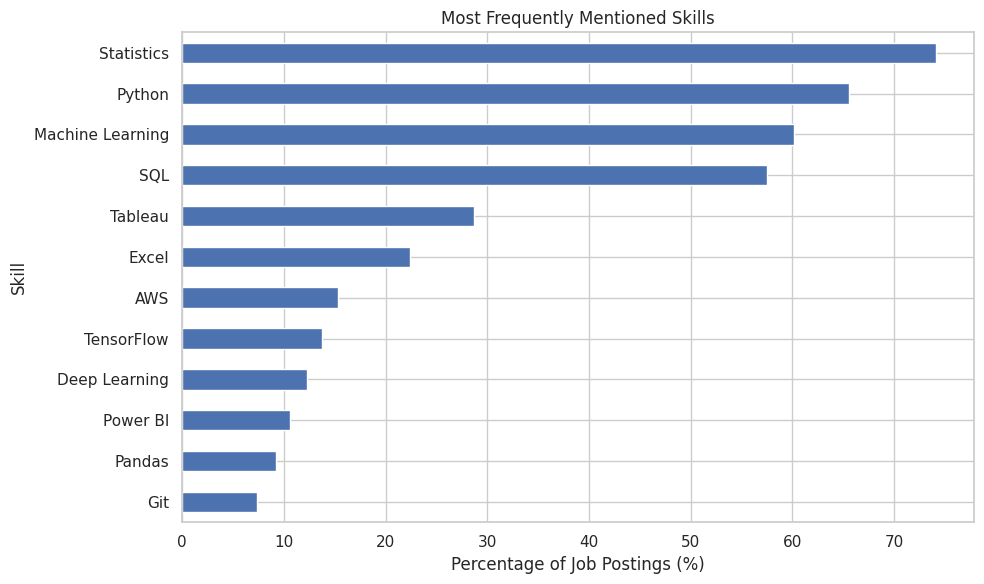

,Python,SQL,Excel,Power BI,Tableau,Pandas,NumPy,Machine Learning,Statistics,Deep Learning,TensorFlow,PyTorch,R Programming,AWS,Spark,Git
role_group,,,,,,,,,,,,,,,,
Data Analyst,30.8,70.1,60.7,17.8,41.1,0.9,0.0,7.5,58.9,0.0,0.0,0.0,0.0,2.8,2.8,0.0
Data Scientist,75.9,53.8,10.9,8.4,24.9,11.8,7.8,75.9,78.7,16.0,17.9,9.0,0.3,19.0,6.7,9.5


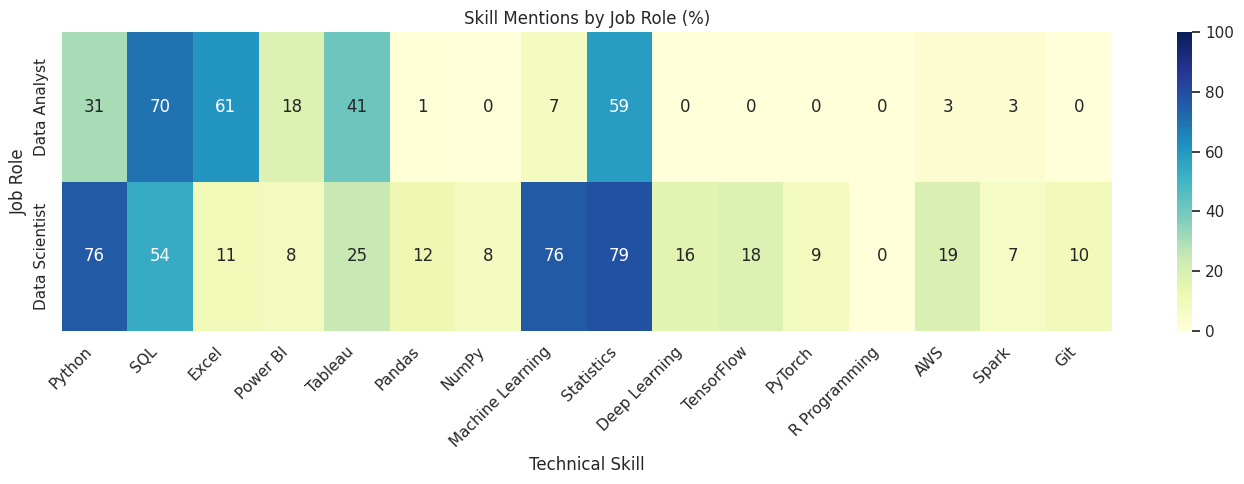

Target role: Data Analyst

Potential skills to learn next:


,mention_rate_percent,already_know
SQL,70.093458,False
Statistics,58.878505,False
Tableau,41.121495,False
Power BI,17.757009,False
Machine Learning,7.476636,False
AWS,2.803738,False
Spark,2.803738,False
Pandas,0.934579,False
NumPy,0.000000,False
Deep Learning,0.000000,False


Target role: Data Analyst

Potential skills to learn next:


,mention_rate_percent,already_know
SQL,70.093458,False
Statistics,58.878505,False
Tableau,41.121495,False
Power BI,17.757009,False
Machine Learning,7.476636,False
AWS,2.803738,False
Spark,2.803738,False
Pandas,0.934579,False
NumPy,0.000000,False
Deep Learning,0.000000,False


In [6]:

import pandas as pd
#extracting the dataset
url = (
    "https://raw.githubusercontent.com/"
    "PlayingNumbers/ds_salary_proj/master/"
    "glassdoor_jobs.csv"
)

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


#inspect and understanding the dataset

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())


#cleaning of data

# Make a working copy
jobs = df.copy()

# Standardize column names for easier coding
jobs.columns = (
    jobs.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(jobs.columns.tolist())



# Keep records with a job title or description
jobs = jobs.dropna(
    subset=["job_title", "job_description"]
).copy()

# Standardize text
jobs["job_title"] = jobs["job_title"].astype(str).str.strip()
jobs["job_description"] = (
    jobs["job_description"].astype(str).str.lower()
)

# Remove exact duplicate records
jobs = jobs.drop_duplicates()

# Create a simple role category
title = jobs["job_title"].str.lower()

jobs["role_group"] = pd.NA

jobs.loc[
    title.str.contains(r"\bdata analyst\b", regex=True),
    "role_group"
] = "Data Analyst"

jobs.loc[
    title.str.contains(r"\bdata scientist\b", regex=True),
    "role_group"
] = "Data Scientist"

jobs.loc[
    title.str.contains(r"\bbusiness analyst\b", regex=True),
    "role_group"
] = "Business Analyst"

# Keep only our three target groups
jobs = jobs.dropna(subset=["role_group"]).copy()

print("Usable job postings:", len(jobs))
display(jobs["role_group"].value_counts().to_frame("job_count"))


#extract the skills from the job descricption

import re

skill_patterns = {
    "Python": r"\bpython\b",
    "SQL": r"\bsql\b",
    "Excel": r"\bexcel\b",
    "Power BI": r"\bpower\s*bi\b",
    "Tableau": r"\btableau\b",
    "Pandas": r"\bpandas\b",
    "NumPy": r"\bnumpy\b",
    "Machine Learning": r"\bmachine learning\b",
    "Statistics": r"\bstatistics?\b|\bstatistical\b",
    "Deep Learning": r"\bdeep learning\b",
    "TensorFlow": r"\btensorflow\b",
    "PyTorch": r"\bpytorch\b",
    "R Programming": r"\br programming\b|\blanguage r\b",
    "AWS": r"\baws\b|amazon web services",
    "Spark": r"\bapache spark\b|\bpyspark\b",
    "Git": r"\bgit\b|\bgitHub\b",
}

# Detect each skill in each job description
for skill, pattern in skill_patterns.items():
    jobs[skill] = jobs["job_description"].apply(
        lambda text: bool(
            re.search(pattern, str(text), flags=re.IGNORECASE)
        )
    )

display(jobs[["job_title", "role_group", "Python", "SQL", "Excel"]].head())




#visulization

skill_columns = list(skill_patterns.keys())

skill_counts = jobs[skill_columns].sum().sort_values(
    ascending=False
)

skill_percentages = (
    jobs[skill_columns].mean().mul(100).sort_values(
        ascending=False
    )
)

summary = pd.DataFrame({
    "job_postings_mentioning_skill": skill_counts,
    "percentage_of_postings": skill_percentages.round(1)
})

display(summary)


#chat
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

top_skills = skill_percentages.head(12).sort_values()

plt.figure(figsize=(10, 6))
top_skills.plot(kind="barh")

plt.title("Most Frequently Mentioned Skills")
plt.xlabel("Percentage of Job Postings (%)")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()


#compare the skill by job descricption

role_skill_percentages = (
    jobs.groupby("role_group")[skill_columns]
    .mean()
    .mul(100)
)

display(role_skill_percentages.round(1))
#heatmap

plt.figure(figsize=(14, 5))

sns.heatmap(
    role_skill_percentages,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

plt.title("Skill Mentions by Job Role (%)")
plt.xlabel("Technical Skill")
plt.ylabel("Job Role")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


#signature feature

# Choose your target role
target_role = "Data Analyst"

# Example only: replace these with your actual skills
my_skills = {"Python", "Excel"}

# Get the skill frequencies for your target role
target_frequencies = role_skill_percentages.loc[target_role]

skill_gap = pd.DataFrame({
    "mention_rate_percent": target_frequencies
})

skill_gap["already_know"] = [
    skill in my_skills for skill in skill_gap.index
]

skill_gap = skill_gap.sort_values(
    "mention_rate_percent", ascending=False
)

print("Target role:", target_role)
print("\nPotential skills to learn next:")

display(
    skill_gap.loc[~skill_gap["already_know"]].head(10)
)


#export result

# Choose your target role
target_role = "Data Analyst"

# Example only: replace these with your actual skills
my_skills = {"Python", "Excel"}

# Get the skill frequencies for your target role
target_frequencies = role_skill_percentages.loc[target_role]

skill_gap = pd.DataFrame({
    "mention_rate_percent": target_frequencies
})

skill_gap["already_know"] = [
    skill in my_skills for skill in skill_gap.index
]

skill_gap = skill_gap.sort_values(
    "mention_rate_percent", ascending=False
)

print("Target role:", target_role)
print("\nPotential skills to learn next:")

display(
    skill_gap.loc[~skill_gap["already_know"]].head(10)
)
